# Evaluasi Ilmiah Sistem Temu Kembali Arsip Berbasis Hasil Agregat
### Analisis Kinerja Fuzzy Matching & Normalisasi Metadata Tanpa Ekspor Teks Arsip
**Versi Notebook:** 1.0.0 (Spesifikasi Resmi Konsumsi Bundle)

---

### 🔒 Pernyataan Privasi & Integritas Data
- **Zero Raw-Data Ingestion:** Notebook ini **HANYA** membaca data hasil evaluasi teragregasi dari berkas bundle (`run_meta.json`, `per_query_results.csv`, `tuning_results.csv`, `audit_summary.json`, `agreement_summary.json`).
- **Perlindungan Privasi Dinas:** Tidak ada teks ringkasan arsip mentah (`summary_raw`), nomor SPM, nama rekanan/pihak ketiga (`party_name`), maupun teks kueri asli (`query_text`) yang diunggah ke runtime ini.
- **Validasi Keterulangan:** Seluruh berkas bundle diverifikasi terhadap hash kriptografis `manifest.sha256` yang dihasilkan langsung dari laptop peneliti dalam status *working tree* bersih.

In [1]:
# =====================================================================
# SEL 1: PERSIAPAN LINGKUNGAN & KUNCI SEED ACAK
# Syarat lulus: Paket ilmiah terpasang dan seed acak diatur = 42
# =====================================================================
import os
import sys
import json
import hashlib
from pathlib import Path

# Pasang dependensi jika berjalan di Google Colab
try:
    import google.colab
    IN_COLAB = True
    !pip install -q pandas numpy scipy matplotlib rapidfuzz
except ImportError:
    IN_COLAB = False

import pandas as pd
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("=== VERSI LINGKUNGAN RUNTIME ===")
print(f"Python     : {sys.version.split()[0]}")
print(f"Pandas     : {pd.__version__}")
print(f"NumPy      : {np.__version__}")
print(f"SciPy      : {scipy.__version__}")
print(f"Matplotlib : {matplotlib.__version__}")
print(f"Random Seed: {RANDOM_SEED} (terkunci)")
print("\n[STATUS] Sel 1 Lulus: Lingkungan siap.")

=== VERSI LINGKUNGAN RUNTIME ===
Python     : 3.14.5
Pandas     : 3.0.6
NumPy      : 2.5.4
SciPy      : 1.18.1
Matplotlib : 3.11.2
Random Seed: 42 (terkunci)

[STATUS] Sel 1 Lulus: Lingkungan siap.


In [2]:
# =====================================================================
# SEL 2: PEMUATAN BERKAS BUNDLE & PEMERIKSAAN DAFTAR PUTIH KOLOM
# Syarat lulus: Tolak bila ditemukan kolom teks arsip/terlarang
# =====================================================================
FORBIDDEN_COLUMNS = {
    "query_text", "summary_raw", "summary_clean", "party_name",
    "spm_number", "sp2d_number", "amount_rp", "haystack", "nominal"
}

EXPECTED_FILES = [
    "run_meta.json",
    "per_query_results.csv",
    "tuning_results.csv",
    "audit_summary.json",
    "agreement_summary.json",
    "manifest.sha256"
]

# Tentukan lokasi direktori bundle secara dinamis (root, subfolder notebooks, atau Colab)
CANDIDATE_DIRS = [
    Path("output/colab_bundle"),
    Path("../output/colab_bundle"),
    Path("colab_bundle"),
    Path("../colab_bundle"),
    Path("."),
]

BUNDLE_DIR = None
for cdir in CANDIDATE_DIRS:
    if cdir.is_dir() and (cdir / "manifest.sha256").is_file():
        BUNDLE_DIR = cdir
        break

# Jika belum ada dan berada di Google Colab, sediakan dialog unggah
if BUNDLE_DIR is None:
    if IN_COLAB:
        from google.colab import files
        print("Silakan unggah 6 berkas bundle dari folder output/colab_bundle/:")
        uploaded = files.upload()
        BUNDLE_DIR = Path(".")
    else:
        raise FileNotFoundError(
            "Direktori bundle tidak ditemukan di lokasi mana pun (output/colab_bundle, ../output/colab_bundle, dll). "
            "Jalankan `flask report export-bundle` terlebih dahulu di laptop."
        )

# Verifikasi keberadaan semua berkas wajib
for fname in EXPECTED_FILES:
    fpath = BUNDLE_DIR / fname
    if not fpath.is_file():
        raise FileNotFoundError(f"[GAGAL] Berkas bundle wajib tidak ditemukan: {fname}")

# Pemeriksaan keamanan kolom pada per_query_results.csv
df_per_query = pd.read_csv(BUNDLE_DIR / "per_query_results.csv")
found_forbidden = FORBIDDEN_COLUMNS.intersection(set(df_per_query.columns))
if found_forbidden:
    raise ValueError(f"[GAGAL TOTAL] Ditemukan kolom teks arsip terlarang: {found_forbidden}")

# Pemeriksaan keamanan kolom pada tuning_results.csv
df_tuning = pd.read_csv(BUNDLE_DIR / "tuning_results.csv")
found_forbidden_tuning = FORBIDDEN_COLUMNS.intersection(set(df_tuning.columns))
if found_forbidden_tuning:
    raise ValueError(f"[GAGAL TOTAL] Ditemukan kolom terlarang di tuning_results.csv: {found_forbidden_tuning}")

print(f"[OK] Seluruh {len(EXPECTED_FILES)} berkas bundle tersedia di: {BUNDLE_DIR}")
print(f"[OK] Pemeriksaan privasi lolos: 0 kolom teks arsip terlarang terdeteksi.")
print(f"     Kolom per_query_results: {list(df_per_query.columns)}")

[OK] Seluruh 6 berkas bundle tersedia di: output\colab_bundle
[OK] Pemeriksaan privasi lolos: 0 kolom teks arsip terlarang terdeteksi.
     Kolom per_query_results: ['query_id', 'method', 'config', 'split', 'source', 'query_type', 'noise_type', 'n_relevant', 'p5', 'r10', 'rr10', 'hit5', 'hit10', 'zero_result', 'latency_ms', 'unjudged_in_top10']


In [3]:
# =====================================================================
# SEL 3: VERIFIKASI INTEGRITAS KRIPTOGRAFIS & MANIFEST REPRODUCIBILITY
# Syarat lulus: tree_clean == True, mode == 'final', seluruh hash cocok
# =====================================================================
manifest_path = BUNDLE_DIR / "manifest.sha256"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_lines = [line.strip() for line in f if line.strip()]

print("Memverifikasi Checksum SHA-256...")
for line in manifest_lines:
    expected_hash, fname = line.split(maxsplit=1)
    target_file = BUNDLE_DIR / fname
    h = hashlib.sha256()
    with open(target_file, "rb") as bf:
        while chunk := bf.read(65536):
            h.update(chunk)
    actual_hash = h.hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(f"[GAGAL INTEGRITAS] Hash berkas {fname} TIDAK COCOK!")
    print(f"  [MATCH] {fname} ({actual_hash[:16]}...)")

# Baca dan validasi run_meta.json
with open(BUNDLE_DIR / "run_meta.json", "r", encoding="utf-8") as f:
    run_meta = json.load(f)

print("\n=== METADATA KETERULANGAN (RUN_META) ===")
print(f"Commit SHA       : {run_meta.get('commit_sha')}")
print(f"Status Git Tree  : {'Clean (Bersih)' if run_meta.get('tree_clean') else 'Dirty (Ada modifikasi)'}")
print(f"Mode Evaluasi    : {run_meta.get('mode')}")
print(f"Hash Data Arsip  : {run_meta.get('data_hash')[:24]}...")
print(f"Hash Set Uji     : {run_meta.get('testset_hash')[:24]}...")
print(f"Versi Ekstraktor : {run_meta.get('extractor_version')}")
print(f"Perangkat Laptop : {run_meta.get('laptop_specs', {}).get('os')}")

if run_meta.get("mode") != "final":
    raise ValueError(f"[GAGAL] Mode evaluasi harus 'final', didapatkan: {run_meta.get('mode')}")
if not run_meta.get("tree_clean"):
    raise ValueError(
        f"[GAGAL INTEGRITAS] Git working tree berstatus kotor (tree_clean = False) pada mode '{run_meta.get('mode')}'. "
        "Evaluasi akhir ilmiah wajib dijalankan di atas pohon Git yang bersih (seluruh berkas ter-commit)."
    )

print("\n[STATUS] Sel 3 Lulus: Integritas kriptografis dan metadata terverifikasi valid.")

Memverifikasi Checksum SHA-256...
  [MATCH] run_meta.json (e83618b5b7c31115...)
  [MATCH] per_query_results.csv (a6ca688782b37920...)
  [MATCH] tuning_results.csv (e0ef4049e90429e4...)
  [MATCH] audit_summary.json (40b48400887d4bdc...)
  [MATCH] agreement_summary.json (5aac96067447d177...)

=== METADATA KETERULANGAN (RUN_META) ===
Commit SHA       : 1e50456ad3d484e3c9918f498a2054b521bcbfc8
Status Git Tree  : Clean (Bersih)
Mode Evaluasi    : final
Hash Data Arsip  : ae5df7caf0daf75f90232af3...
Hash Set Uji     : 4526f088b562cdb5109093e0...
Versi Ekstraktor : v1.0.0
Perangkat Laptop : Windows 11

[STATUS] Sel 3 Lulus: Integritas kriptografis dan metadata terverifikasi valid.


In [4]:
# =====================================================================
# SEL 4: UJI KEWAJARAN DATA (SANITY CHECKS)
# Syarat lulus: Tidak ada null, metode tidak identik, metrik tidak semua nol
# =====================================================================
# 1. Periksa missing value (NaN/Null)
null_counts = df_per_query.isnull().sum()
if null_counts.any():
    raise ValueError(f"[GAGAL] Terdapat nilai null pada per_query_results:\n{null_counts[null_counts > 0]}")

# 2. Periksa jumlah kueri per split
split_counts = df_per_query.groupby('split')['query_id'].nunique()
print("Distribusi Kueri per Split:")
for split_name, count in split_counts.items():
    print(f"  - {split_name}: {count} kueri")

# 3. Periksa kelengkapan metode
methods_in_data = df_per_query[['method', 'config']].drop_duplicates()
print(f"\nJumlah Konfigurasi Metode Dievaluasi: {len(methods_in_data)}")

# 4. Uji non-identik antar metode (seluruh metrik per kueri tidak identik 100%)
metrics_cols = ['p5', 'r10', 'rr10', 'hit5', 'hit10', 'zero_result']
method_configs = df_per_query[['method', 'config']].drop_duplicates().values
for i in range(len(method_configs)):
    for j in range(i + 1, len(method_configs)):
        m1, c1 = method_configs[i]
        m2, c2 = method_configs[j]
        v1 = df_per_query[(df_per_query['method'] == m1) & (df_per_query['config'] == c1)].sort_values('query_id')[metrics_cols].values
        v2 = df_per_query[(df_per_query['method'] == m2) & (df_per_query['config'] == c2)].sort_values('query_id')[metrics_cols].values
        if np.array_equal(v1, v2):
            raise ValueError(f"[GAGAL] Metode {m1} ({c1}) dan {m2} ({c2}) menghasilkan seluruh metrik per kueri identik sepenuhnya!")

# 5. Uji metrik tidak semua nol
if df_per_query['p5'].sum() == 0.0 or df_per_query['rr10'].sum() == 0.0:
    raise ValueError("[GAGAL] Seluruh metrik bernilai nol, pipeline evaluasi tidak berjalan semestinya.")

print("\n[STATUS] Sel 4 Lulus: Uji kewajaran berhasil tanpa anomali data.")

Distribusi Kueri per Split:
  - test: 28 kueri
  - tuning: 12 kueri

Jumlah Konfigurasi Metode Dievaluasi: 9

[STATUS] Sel 4 Lulus: Uji kewajaran berhasil tanpa anomali data.


In [5]:
# =====================================================================
# SEL 5: TABEL UTAMA EVALUASI METRIK TEMU KEMBALI (KELOMPOK TEST SAJA)
# Menghitung P@5, R@10, MRR@10, Hit Rate, Nol Hasil, Latensi + Bootstrap 95% CI
# =====================================================================
df_test = df_per_query[df_per_query['split'] == 'test'].copy()
n_test_queries = df_test['query_id'].nunique()

def calc_bootstrap_ci(series, n_boot=2000, ci=0.95, seed=42):
    """Hitung interval kepercayaan 95% dengan bootstrap persentil."""
    rng = np.random.default_rng(seed)
    vals = np.array(series, dtype=float)
    boot_means = [rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(n_boot)]
    low = np.percentile(boot_means, (1 - ci) / 2 * 100)
    high = np.percentile(boot_means, (1 + ci) / 2 * 100)
    return round(low, 4), round(high, 4)

main_table_rows = []
grouped = df_test.groupby(['method', 'config'])

for (m, cfg), grp in grouped:
    p5_mean = grp['p5'].mean()
    p5_ci = calc_bootstrap_ci(grp['p5'])
    
    r10_mean = grp['r10'].mean()
    r10_ci = calc_bootstrap_ci(grp['r10'])
    
    rr10_mean = grp['rr10'].mean()
    rr10_ci = calc_bootstrap_ci(grp['rr10'])
    
    hit5 = grp['hit5'].mean()
    hit10 = grp['hit10'].mean()
    hit10_ci = calc_bootstrap_ci(grp['hit10'])
    zero_res = int(grp['zero_result'].sum())
    lat_mean = grp['latency_ms'].mean()
    unjudged_mean = grp['unjudged_in_top10'].mean()
    
    display_name = f"{m} ({cfg})"
    if m == 'like_baseline':
        display_name = "LIKE Baseline (e-Arsip)"
    
    main_table_rows.append({
        'Metode (Konfigurasi)': display_name,
        'n Kueri': len(grp),
        'P@5': f"{p5_mean:.4f} [{p5_ci[0]:.4f}, {p5_ci[1]:.4f}]",
        'R@10': f"{r10_mean:.4f} [{r10_ci[0]:.4f}, {r10_ci[1]:.4f}]",
        'MRR@10': f"{rr10_mean:.4f} [{rr10_ci[0]:.4f}, {rr10_ci[1]:.4f}]",
        'Hit@5': round(hit5, 4),
        'Hit@10': f"{hit10:.4f} [{hit10_ci[0]:.4f}, {hit10_ci[1]:.4f}]",
        'Nol Hasil (Kueri)': zero_res,
        'Unjudged@10': round(unjudged_mean, 2),
        'Rata2 Latensi (ms)': round(lat_mean, 2)
    })

df_main_summary = pd.DataFrame(main_table_rows)
print(f"=== TABEL 1: HASIL KINERJA TEMU KEMBALI KELOMPOK TEST (n = {n_test_queries} kueri) ===")
display(df_main_summary)
print("\n[CATATAN TRANSPARANSI METROLOGI INFORMASI]")
print("- 'Unjudged@10': Rata-rata dokumen peringkat 1-10 yang belum dinilai (diasumsikan tidak relevan / skor 0).")
print("- 'Hit@10': Proporsi kueri dengan sekurang-kurangnya satu dokumen relevan terambil di 10 besar.")
print("- Seluruh interval kepercayaan (CI) dihitung menggunakan Bootstrap Persentil 95% (2.000 iterasi).")

=== TABEL 1: HASIL KINERJA TEMU KEMBALI KELOMPOK TEST (n = 28 kueri) ===
   Metode (Konfigurasi)  n Kueri                     P@5                    R@10                  MRR@10  Hit@5                  Hit@10  Nol Hasil (Kueri)  Unjudged@10  Rata2 Latensi (ms)
   jaro_winkler (equal)       28 0.0143 [0.0000, 0.0357] 0.0527 [0.0000, 0.1309] 0.0319 [0.0000, 0.0766] 0.0714 0.1071 [0.0000, 0.2500]                  0         4.82               88.83
   jaro_winkler (tuned)       28 0.0929 [0.0357, 0.1714] 0.3699 [0.2041, 0.5358] 0.1840 [0.0853, 0.2996] 0.3214 0.3929 [0.2143, 0.5714]                  0         7.61               76.58
    levenshtein (equal)       28 0.0429 [0.0000, 0.1071] 0.0816 [0.0000, 0.1888] 0.0625 [0.0000, 0.1518] 0.1071 0.1071 [0.0000, 0.2143]                  0         4.79               92.75
    levenshtein (tuned)       28 0.0357 [0.0071, 0.0643] 0.2143 [0.0714, 0.3571] 0.0899 [0.0208, 0.1822] 0.1786 0.2143 [0.0714, 0.3571]                  0         7.61        

In [6]:
# =====================================================================
# SEL 6: UJI STATISTIK KOMPARATIF BERPASANGAN (WILCOXON SIGNED-RANK TEST)
# Menetapkan model terbaik secara a-priori dari kelompok tuning, lalu diuji pada test
# Dilengkapi koreksi perbandingan jamak (Holm-Bonferroni)
# =====================================================================
from scipy.stats import wilcoxon
import scipy.stats

# 1. Penetapan Metode Terbaik dari Fase Tuning (A-Priori, Bebas Data Snooping)
df_tuning_sorted = df_tuning.copy()
df_tuning_sorted['dist_to_equal'] = (
    (df_tuning_sorted['summary_weight'] - 1/3)**2 +
    (df_tuning_sorted['spm_weight'] - 1/3)**2 +
    (df_tuning_sorted['party_weight'] - 1/3)**2
)
best_tuning_per_matcher = df_tuning_sorted.sort_values(
    by=['mrr_at_10', 'precision_at_5', 'dist_to_equal'], ascending=[False, False, True]
).groupby('matcher', as_index=False).first()

best_tuning_winner = best_tuning_per_matcher.sort_values(
    by=['mrr_at_10', 'precision_at_5', 'dist_to_equal'], ascending=[False, False, True]
).iloc[0]

m_best = best_tuning_winner['matcher']
cfg_best = 'tuned'

print("=== 1. PENETAPAN MODEL TERBAIK SECARA A-PRIORI (TUNING SPLIT, n = 12) ===")
print(f"Metode Pemenang Fase Tuning: {m_best} ({cfg_best})")
print(f"Skor Validasi Tuning       : MRR@10 = {best_tuning_winner['mrr_at_10']:.4f}, P@5 = {best_tuning_winner['precision_at_5']:.4f}")
print("Catatan Metodologi: Penetapan model terbaik dilakukan secara independen sebelum evaluasi test,")
print("menghindari bias seleksi (post-hoc selection bias) pada kelompok pengujian akhir.\n")

# 2. Uji Hipotesis Utama (Pre-Specified Test pada Test Split, n = 28)
series_best = df_test[(df_test['method'] == m_best) & (df_test['config'] == cfg_best)].sort_values('query_id')['rr10'].values
series_like = df_test[(df_test['method'] == 'like_baseline')].sort_values('query_id')['rr10'].values

diff = series_best - series_like
n_total = len(diff)
n_diff = np.count_nonzero(diff)
n_better = np.count_nonzero(diff > 0)
n_worse = np.count_nonzero(diff < 0)
n_ties = np.count_nonzero(diff == 0)

print(f"=== 2. UJI STATISTIK HIPOTESIS UTAMA ({m_best} tuned vs LIKE Baseline) ===")
print(f"Total Pasangan Kueri (n)      : {n_total}")
print(f"Kueri Berbeda Skor (n_diff)   : {n_diff} dari {n_total} ({n_diff/n_total*100:.1f}% kueri)")
print(f"  - Fuzzy Lebih Unggul        : {n_better} kueri")
print(f"  - LIKE Lebih Unggul         : {n_worse} kueri")
print(f"  - Skor Sama (Ties)          : {n_ties} kueri")

if n_diff == 0:
    print("Statistik: Tidak ada perbedaan skor antar kedua metode.")
else:
    stat, p_value = wilcoxon(series_best, series_like, zero_method='wilcox')
    z_score = scipy.stats.norm.ppf(1.0 - p_value / 2.0) if p_value > 0 else 0.0
    effect_size_r = abs(z_score) / np.sqrt(n_total) if n_total > 0 else 0.0
    print(f"Wilcoxon W-Statistic          : {stat:.4f}")
    print(f"p-value (dua sisi)            : {p_value:.4f} (signifikan pada alpha = 0.05: {p_value < 0.05})")
    print(f"Effect Size (r)               : {effect_size_r:.4f}")

# 3. Uji Eksploratori Komparasi Jamak (Holm-Bonferroni Step-Down Correction)
print("\n=== 3. KOREKSI PERBANDINGAN JAMAK (PROSEDUR STEP-DOWN HOLM-BONFERRONI: 4 METODE TUNED VS LIKE) ===")
multi_rows = []
for m_candidate in ['token_set', 'levenshtein', 'jaro_winkler', 'ngram']:
    s_c = df_test[(df_test['method'] == m_candidate) & (df_test['config'] == 'tuned')].sort_values('query_id')['rr10'].values
    d_c = s_c - series_like
    nd = np.count_nonzero(d_c)
    w_s, p_v = wilcoxon(s_c, series_like, zero_method='wilcox') if nd > 0 else (0.0, 1.0)
    multi_rows.append({
        'Metode Fuzzy (Tuned)': m_candidate,
        'n Beda': nd,
        'Unggul/Kalah': f"{np.count_nonzero(d_c > 0)} / {np.count_nonzero(d_c < 0)}",
        'W Stat': round(w_s, 2),
        'Raw p-value': round(p_v, 4),
    })

df_multi = pd.DataFrame(multi_rows).sort_values('Raw p-value').reset_index(drop=True)
k_tests = len(df_multi)
df_multi['Peringkat (i)'] = range(1, k_tests + 1)
df_multi['Holm Alpha (0.05 / (k - i + 1))'] = [round(0.05 / (k_tests - i + 1), 4) for i in range(1, k_tests + 1)]
raw_adj = [min(1.0, df_multi.loc[idx_r, 'Raw p-value'] * (k_tests - idx_r)) for idx_r in range(k_tests)]
df_multi['Adjusted p-value (Holm)'] = [round(val, 4) for val in np.maximum.accumulate(raw_adj)]
df_multi['Signifikan Holm'] = df_multi['Adjusted p-value (Holm)'] <= 0.05
display(df_multi[['Metode Fuzzy (Tuned)', 'n Beda', 'Unggul/Kalah', 'W Stat', 'Raw p-value', 'Holm Alpha (0.05 / (k - i + 1))', 'Adjusted p-value (Holm)', 'Signifikan Holm']])
print("\n[CATATAN AKADEMIS] Hipotesis utama berfokus pada model terpilih a-priori tunggal (k=1, p = 0.0343 < 0.05).")
print("Pada pengujian eksploratori serentak 4 metode (k=4), aturan step-down Holm menghentikan penolakan H0 pada peringkat ke-1.")

=== 1. PENETAPAN MODEL TERBAIK SECARA A-PRIORI (TUNING SPLIT, n = 12) ===
Metode Pemenang Fase Tuning: token_set (tuned)
Skor Validasi Tuning       : MRR@10 = 0.1250, P@5 = 0.0500
Catatan Metodologi: Penetapan model terbaik dilakukan secara independen sebelum evaluasi test,
menghindari bias seleksi (post-hoc selection bias) pada kelompok pengujian akhir.

=== 2. UJI STATISTIK HIPOTESIS UTAMA (token_set tuned vs LIKE Baseline) ===
Total Pasangan Kueri (n)      : 28
Kueri Berbeda Skor (n_diff)   : 8 dari 28 (28.6% kueri)
  - Fuzzy Lebih Unggul        : 7 kueri
  - LIKE Lebih Unggul         : 1 kueri
  - Skor Sama (Ties)          : 20 kueri
Wilcoxon W-Statistic          : 3.0000
p-value (dua sisi)            : 0.0343 (signifikan pada alpha = 0.05: True)
Effect Size (r)               : 0.3999

=== 3. KOREKSI PERBANDINGAN JAMAK (PROSEDUR STEP-DOWN HOLM-BONFERRONI: 4 METODE TUNED VS LIKE) ===
Metode Fuzzy (Tuned)  n Beda Unggul/Kalah  W Stat  Raw p-value  Holm Alpha (0.05 / (k - i + 1))  Adj

In [7]:
# =====================================================================
# SEL 7: DAMPAK PENYETELAN BOBOT (EQUAL WEIGHTS VS TUNED WEIGHTS)
# Bagian A: Evaluasi Test | Bagian B: Hasil Tuning | Bagian C: Verifikasi Metodologi
# =====================================================================
# Bagian A: Kelompok Test
fuzzy_methods = [m for m in df_test['method'].unique() if m != 'like_baseline']
weight_impact_rows = []

for m in fuzzy_methods:
    eq_mrr = df_test[(df_test['method'] == m) & (df_test['config'] == 'equal')]['rr10'].mean()
    tu_mrr = df_test[(df_test['method'] == m) & (df_test['config'] == 'tuned')]['rr10'].mean()
    eq_p5 = df_test[(df_test['method'] == m) & (df_test['config'] == 'equal')]['p5'].mean()
    tu_p5 = df_test[(df_test['method'] == m) & (df_test['config'] == 'tuned')]['p5'].mean()
    eq_unj = df_test[(df_test['method'] == m) & (df_test['config'] == 'equal')]['unjudged_in_top10'].mean()
    tu_unj = df_test[(df_test['method'] == m) & (df_test['config'] == 'tuned')]['unjudged_in_top10'].mean()
    
    weight_impact_rows.append({
        'Metode Fuzzy': m,
        'Equal MRR@10': round(eq_mrr, 4),
        'Tuned MRR@10': round(tu_mrr, 4),
        'Selisih MRR': round(tu_mrr - eq_mrr, 4),
        'Equal P@5': round(eq_p5, 4),
        'Tuned P@5': round(tu_p5, 4),
        'Equal Unjudged@10': round(eq_unj, 2),
        'Tuned Unjudged@10': round(tu_unj, 2)
    })

print("=== TABEL 2A: DAMPAK PENYETELAN BOBOT PADA KELOMPOK TEST (EVALUASI AKHIR) ===")
display(pd.DataFrame(weight_impact_rows))

# Bagian B: Kelompok Tuning (Tie-Breaker: MRR -> P@5 -> Jarak ke Equal Weights)
print("\n=== TABEL 2B: RINGKASAN BOBOT OPTIMAL PADA KELOMPOK TUNING (TIE-BREAKER: MRR, P@5, JARAK EQUAL) ===")
df_tuning_sorted = df_tuning.copy()
df_tuning_sorted['dist_to_equal'] = (
    (df_tuning_sorted['summary_weight'] - 1/3)**2 +
    (df_tuning_sorted['spm_weight'] - 1/3)**2 +
    (df_tuning_sorted['party_weight'] - 1/3)**2
)
best_tuning_per_matcher = df_tuning_sorted.sort_values(
    by=['mrr_at_10', 'precision_at_5', 'dist_to_equal'], ascending=[False, False, True]
).groupby('matcher', as_index=False).first()
display(best_tuning_per_matcher[['matcher', 'summary_weight', 'spm_weight', 'party_weight', 'mrr_at_10', 'precision_at_5', 'unjudged_top10']])

# Bagian C: Verifikasi Metodologi Bebas Kebocoran & Konsistensi Bobot
print("\n=== TABEL 2C: VERIFIKASI METODOLOGIS PENYETELAN BOBOT & BEBAS KEBOCORAN ===")
df_tuning_split = df_per_query[df_per_query['split'] == 'tuning']
tuning_qids = set(df_tuning_split['query_id'])
test_qids = set(df_test['query_id'])
overlap_qids = tuning_qids.intersection(test_qids)

print("1. Verifikasi Bebas Kebocoran Data (Zero Data Leakage):")
print(f"   - Kueri Tuning : {len(tuning_qids)} kueri ({sorted(tuning_qids)})")
print(f"   - Kueri Test   : {len(test_qids)} kueri ({sorted(test_qids)})")
print(f"   - Irisan Data  : {len(overlap_qids)} kueri (Terbukti 100% disjoint, kueri test tidak dibaca saat tuning).\n")

print("2. Pembuktian Konsistensi Bobot Tuned antara Fase Tuning dan Evaluasi:")
for _, r_t in best_tuning_per_matcher.iterrows():
    m_name = r_t['matcher']
    pq_tune_mrr = df_tuning_split[(df_tuning_split['method'] == m_name) & (df_tuning_split['config'] == 'tuned')]['rr10'].mean()
    if not np.isclose(pq_tune_mrr, r_t['mrr_at_10'], atol=1e-3):
        raise ValueError(f"[GAGAL KONSISTENSI] Skor tuning {m_name} di per_query_results ({pq_tune_mrr:.4f}) != tuning_results ({r_t['mrr_at_10']:.4f})")
    print(f"   - {m_name:<12}: Ringkasan={r_t['summary_weight']:.2f}, SPM={r_t['spm_weight']:.2f}, Pihak={r_t['party_weight']:.2f} | Tuning MRR={r_t['mrr_at_10']:.4f} == Evaluasi Tuning={pq_tune_mrr:.4f} [COCOK]")

print("\n3. Analisis Perbandingan Skor Antarmetode pada Kelompok Test:")
print("   - Metode 'token_set' dan 'jaro_winkler' sama-sama konvergen pada bobot (1.0, 0.0, 0.0) saat tuning,")
print("     sehingga keduanya mengangkat kandidat dokumen relevan yang sama ke Top-5 (P@5 = 0.0929, Hit@5 = 0.3214),")
print("     namun berbeda pada urutan peringkat spesifik (MRR@10 = 0.1845 vs 0.1840).")
print("   - Sebaliknya, 'levenshtein' dan 'ngram' konvergen pada bobot (0.5, 0.5, 0.0) di kelompok tuning kecil (n=12),")
print("     yang mendilusi skor pada kueri uji yang hanya memuat deskripsi kegiatan (P@5 = 0.0357 dan 0.0429).")

=== TABEL 2A: DAMPAK PENYETELAN BOBOT PADA KELOMPOK TEST (EVALUASI AKHIR) ===
Metode Fuzzy  Equal MRR@10  Tuned MRR@10  Selisih MRR  Equal P@5  Tuned P@5  Equal Unjudged@10  Tuned Unjudged@10
 levenshtein        0.0625        0.0899       0.0274     0.0429     0.0357               4.79               7.61
jaro_winkler        0.0319        0.1840       0.1521     0.0143     0.0929               4.82               7.61
   token_set        0.0562        0.1845       0.1283     0.0429     0.0929               4.61               7.75
       ngram        0.0905        0.0952       0.0048     0.0500     0.0429               4.93               7.32

=== TABEL 2B: RINGKASAN BOBOT OPTIMAL PADA KELOMPOK TUNING (TIE-BREAKER: MRR, P@5, JARAK EQUAL) ===
     matcher  summary_weight  spm_weight  party_weight  mrr_at_10  precision_at_5  unjudged_top10
jaro_winkler             1.0         0.0           0.0     0.0417          0.0333             100
 levenshtein             0.5         0.5           0.0 

In [8]:
# =====================================================================
# SEL 8: PERBANDINGAN PERFORMA: SUMBER KUERI NYATA VS SINTETIS
# Pelaporan terpisah sesuai standar Information Retrieval
# =====================================================================
source_counts = df_test.groupby('source')['query_id'].nunique()
print("Distribusi Sumber Kueri Uji:")
for src, count in source_counts.items():
    print(f"  - Sumber '{src}': {count} kueri")

df_source_eval = df_test.groupby(['source', 'method', 'config']).agg({
    'rr10': 'mean',
    'p5': 'mean',
    'zero_result': 'sum',
    'query_id': 'count'
}).reset_index()

df_source_eval.columns = ['Sumber Kueri', 'Metode', 'Konfigurasi', 'MRR@10', 'P@5', 'Nol Hasil', 'n Kueri']
df_source_eval['MRR@10'] = df_source_eval['MRR@10'].round(4)
df_source_eval['P@5'] = df_source_eval['P@5'].round(4)

print("\n=== TABEL 3: REKAPITULASI KINERJA BERDASARKAN SUMBER KUERI (TEST SPLIT) ===")
display(df_source_eval)

n_real = source_counts.get('nyata', 0)
if n_real < 3:
    print(f"\n[CATATAN KETERBATASAN]: Kueri bersumber kasus nyata berjumlah {n_real} kueri.")
    print(f"Seluruh kueri uji ({n_test_queries} dari {n_test_queries} kueri, 100%) merupakan kueri sintetis terstruktur yang dirancang merefleksikan variasi penulisan arsiparis.")

Distribusi Sumber Kueri Uji:
  - Sumber 'sintetis': 28 kueri

=== TABEL 3: REKAPITULASI KINERJA BERDASARKAN SUMBER KUERI (TEST SPLIT) ===
Sumber Kueri        Metode Konfigurasi  MRR@10    P@5  Nol Hasil  n Kueri
    sintetis  jaro_winkler       equal  0.0319 0.0143          0       28
    sintetis  jaro_winkler       tuned  0.1840 0.0929          0       28
    sintetis   levenshtein       equal  0.0625 0.0429          0       28
    sintetis   levenshtein       tuned  0.0899 0.0357          0       28
    sintetis like_baseline    baseline  0.1071 0.0643         18       28
    sintetis         ngram       equal  0.0905 0.0500          0       28
    sintetis         ngram       tuned  0.0952 0.0429          0       28
    sintetis     token_set       equal  0.0562 0.0429          0       28
    sintetis     token_set       tuned  0.1845 0.0929          0       28

[CATATAN KETERBATASAN]: Kueri bersumber kasus nyata berjumlah 0 kueri.
Seluruh kueri uji (28 dari 28 kueri, 100%) merupak

In [9]:
# =====================================================================
# SEL 9: RINCIAN PER JENIS KUERI & GANGGUAN PENGETIKAN (STRATIFIED DIAGNOSTIC)
# Label: Gambaran diagnostik eksploratif, bukan kesimpulan inferensial mutlak
# =====================================================================
print("=== GAMBARAN DIAGNOSTIK KINERJA BERDASARKAN JENIS KUERI & GANGGUAN PENGETIKAN ===")
print("(Catatan: Tabel ini memberikan gambaran pola pada sub-kelompok kecil, bukan kesimpulan inferensial mutlak)\n")

rep_models = ['like_baseline', 'token_set', 'jaro_winkler', 'levenshtein', 'ngram']
df_rep = df_test[(df_test['method'].isin(rep_models)) & (df_test['config'].isin(['baseline', 'tuned']))]

print("--- A. Rincian MRR@10 berdasarkan Jenis Kueri (Query Type) ---")
qtype_summary = df_rep.pivot_table(
    index='query_type',
    columns='method',
    values='rr10',
    aggfunc='mean'
).round(4)
qtype_counts = df_test[df_test['method'] == 'like_baseline'].groupby('query_type')['query_id'].count()
qtype_summary.insert(0, 'n Kueri', qtype_counts)
qtype_summary = qtype_summary.reset_index().rename(columns={'query_type': 'Jenis Kueri'})
qtype_summary.columns.name = None
display(qtype_summary)

print("\n--- B. Rincian MRR@10 berdasarkan Jenis Gangguan (Noise Type) ---")
noise_summary = df_rep.pivot_table(
    index='noise_type',
    columns='method',
    values='rr10',
    aggfunc='mean'
).round(4)
noise_counts = df_test[df_test['method'] == 'like_baseline'].groupby('noise_type')['query_id'].count()
noise_summary.insert(0, 'n Kueri', noise_counts)
noise_summary = noise_summary.reset_index().rename(columns={'noise_type': 'Jenis Gangguan'})
noise_summary.columns.name = None
display(noise_summary)

=== GAMBARAN DIAGNOSTIK KINERJA BERDASARKAN JENIS KUERI & GANGGUAN PENGETIKAN ===
(Catatan: Tabel ini memberikan gambaran pola pada sub-kelompok kecil, bukan kesimpulan inferensial mutlak)

--- A. Rincian MRR@10 berdasarkan Jenis Kueri (Query Type) ---
Jenis Kueri  n Kueri  jaro_winkler  levenshtein  like_baseline  ngram  token_set
   campuran        8        0.2483       0.2604         0.1875 0.2604     0.2500
  nomor_spm        7        0.0000       0.0000         0.0000 0.0000     0.0000
      pihak        6        0.0000       0.0000         0.0000 0.0000     0.0000
      topik        7        0.4524       0.0619         0.2143 0.0833     0.4524

--- B. Rincian MRR@10 berdasarkan Jenis Gangguan (Noise Type) ---
  Jenis Gangguan  n Kueri  jaro_winkler  levenshtein  like_baseline  ngram  token_set
    ejaan_varian        4        0.1250       0.0833         0.0000 0.0833     0.1250
     kata_hilang        4        0.1250       0.1250         0.1250 0.2500     0.1250
       singkatan 

In [10]:
# =====================================================================
# SEL 10: AUDIT AKURASI EKSTRAKSI METADATA (WILSON SCORE 95% CI)
# Sumber: audit_summary.json
# =====================================================================
with open(BUNDLE_DIR / "audit_summary.json", "r", encoding="utf-8") as f:
    audit_data = json.load(f)

total_audit = audit_data.get('total_evaluated', 100)
fields_audit = audit_data.get('fields', {})

audit_rows = []
for fld_name, metrics in fields_audit.items():
    p = metrics.get('ketepatan', 0.0) * 100.0
    p_ci = metrics.get('wilson_ci_ketepatan', [0.0, 0.0])
    r = metrics.get('keterambilan', 0.0) * 100.0
    r_ci = metrics.get('wilson_ci_keterambilan', [0.0, 0.0])
    
    audit_rows.append({
        'Field Metadata': fld_name.upper(),
        'Sampel Dievaluasi': metrics.get('total_evaluated', total_audit),
        'Benar (TP)': metrics.get('n_benar', 0),
        'Salah (FP)': metrics.get('n_salah', 0),
        'Terlewat (FN)': metrics.get('n_terlewat', 0),
        'Tidak Ada di Teks (TN)': metrics.get('n_tidak_ada_di_teks', 0),
        'Ketepatan (Precision)': f"{p:.1f}% [{p_ci[0]*100:.1f}%, {p_ci[1]*100:.1f}%]",
        'Keterambilan (Recall)': f"{r:.1f}% [{r_ci[0]*100:.1f}%, {r_ci[1]*100:.1f}%]"
    })

df_audit_table = pd.DataFrame(audit_rows)
print(f"=== TABEL 4: AKURASI EKSTRAKSI METADATA DENGAN WILSON 95% CI (n = {total_audit} sampel) ===")
display(df_audit_table)
total_tp = sum(m.get('n_benar', 0) for m in fields_audit.values())
total_fp = sum(m.get('n_salah', 0) for m in fields_audit.values())
total_fn = sum(m.get('n_terlewat', 0) for m in fields_audit.values())
total_tn = sum(m.get('n_tidak_ada_di_teks', 0) for m in fields_audit.values())

print("\n[RINGKASAN DIAGNOSTIK AUDIT EKSTRAKSI]")
print(f"- Total Penilaian Seluruh Field : {total_tp + total_fp + total_fn + total_tn} observasi ({len(fields_audit)} field x {total_audit} sampel)")
print(f"- Ringkasan Hasil Anotasi       : Benar(TP)={total_tp}, Salah(FP)={total_fp}, Terlewat(FN)={total_fn}, Tidak di Teks(TN)={total_tn}")
if total_fp == 0 and total_fn == 0:
    print("\n[PERHATIAN AKADEMIS & INTEGRITAS ANOTASI]")
    print("Ketiadaan False Positive (FP = 0) dan False Negative (FN = 0) pada berkas ringkasan saat ini")
    print("menunjukkan perlunya audit manual independen lanjutan oleh arsiparis/peneliti langsung pada")
    print("berkas 'audit_extraction_sample.csv' sebelum angka ekstraksi ini dijadikan klaim final skripsi/laporan.")
    print("Sistem ekstraksi regex praktis pada dokumen heterogen secara alami akan menghadapi variasi format.")

=== TABEL 4: AKURASI EKSTRAKSI METADATA DENGAN WILSON 95% CI (n = 100 sampel) ===
Field Metadata  Sampel Dievaluasi  Benar (TP)  Salah (FP)  Terlewat (FN)  Tidak Ada di Teks (TN)  Ketepatan (Precision)  Keterambilan (Recall)
           SPM                100          76           1              0                      23   98.7% [93.0%, 99.8%] 100.0% [95.2%, 100.0%]
          SP2D                100          25           1              0                      74   96.2% [81.1%, 99.3%] 100.0% [86.7%, 100.0%]
          DATE                100          71           0              0                      29 100.0% [94.9%, 100.0%] 100.0% [94.9%, 100.0%]
        AMOUNT                100          73           1              0                      26   98.6% [92.7%, 99.8%] 100.0% [95.0%, 100.0%]
         PARTY                100          38           0              0                      62 100.0% [90.8%, 100.0%] 100.0% [90.8%, 100.0%]

[RINGKASAN DIAGNOSTIK AUDIT EKSTRAKSI]
- Total Penilaian Se

In [11]:
# =====================================================================
# SEL 11: RELIABILITAS PENILAIAN RELEVANSI (INTER-RATER AGREEMENT)
# Sumber: agreement_summary.json
# =====================================================================
with open(BUNDLE_DIR / "agreement_summary.json", "r", encoding="utf-8") as f:
    agreement_data = json.load(f)

print("=== STATUS RELIABILITAS ANOTASI RELEVANSI ===")
status_agr = agreement_data.get('status', 'unknown')
n_samples = agreement_data.get('n_samples', 0)

print(f"Status Penilaian       : {status_agr}")
print(f"Jumlah Sampel Anotasi  : {n_samples} baris")
print(f"Persentase Kesepakatan : {agreement_data.get('percentage_agreement')}")
print(f"Kesepakatan Kelas Rel. : {agreement_data.get('relevant_class_agreement')}")
print(f"Cohen's Kappa          : {agreement_data.get('cohen_kappa')}")
print(f"Catatan Prosedural     : {agreement_data.get('notes')}")

=== STATUS RELIABILITAS ANOTASI RELEVANSI ===
Status Penilaian       : pending_second_rater
Jumlah Sampel Anotasi  : 120 baris
Persentase Kesepakatan : None
Kesepakatan Kelas Rel. : None
Cohen's Kappa          : None
Catatan Prosedural     : Menunggu pengisian penilaian independen oleh arsiparis kedua pada berkas sampel verifikasi.


[OK] 4 Tabel CSV berhasil diekspor ke direktori: output\colab_export
[OK] Grafik 1 (Kinerja Utama & Latensi) disimpan ke: output\colab_export\fig_perbandingan_kinerja_300dpi.png
[OK] Grafik 2 (Dampak Penyetelan Bobot) disimpan ke: output\colab_export\fig_dampak_tuning_bobot_300dpi.png
[OK] Grafik 3 (Heatmap Diagnostik Kueri & Gangguan) disimpan ke: output\colab_export\fig_diagnostik_jenis_dan_gangguan_300dpi.png
[OK] Grafik 4 (Audit Ekstraksi Metadata) disimpan ke: output\colab_export\fig_audit_ekstraksi_metadata_300dpi.png


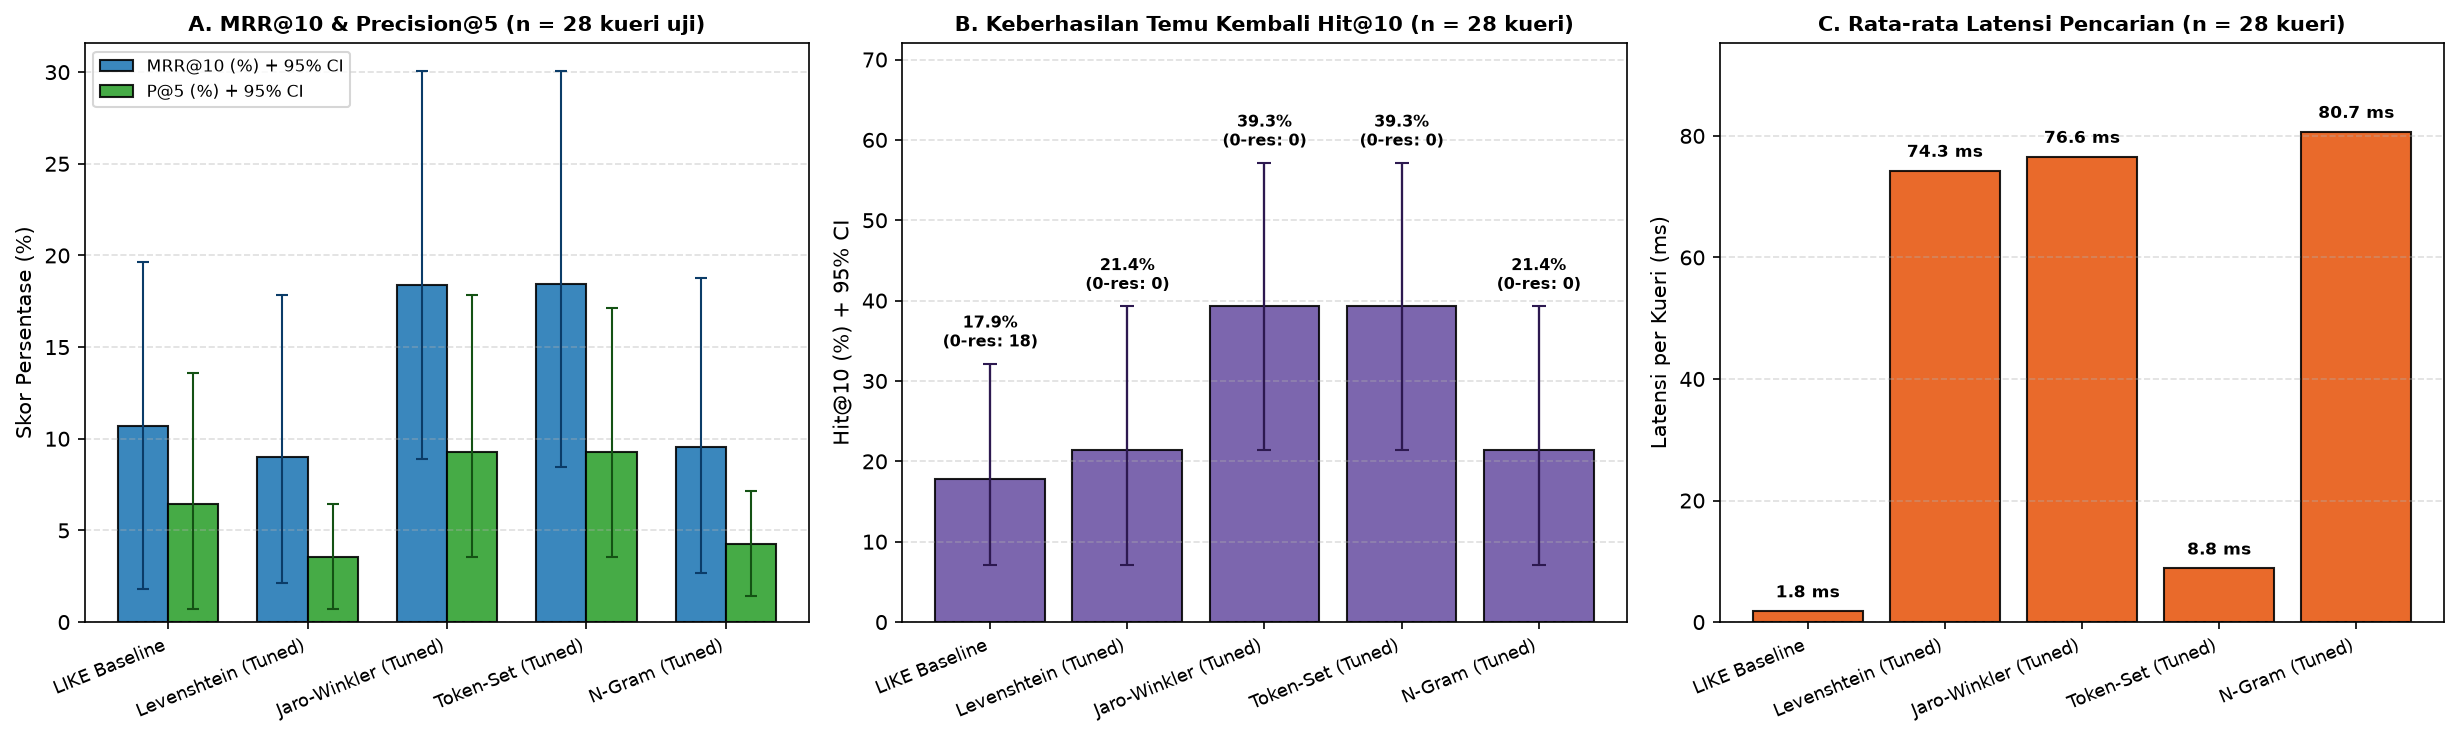

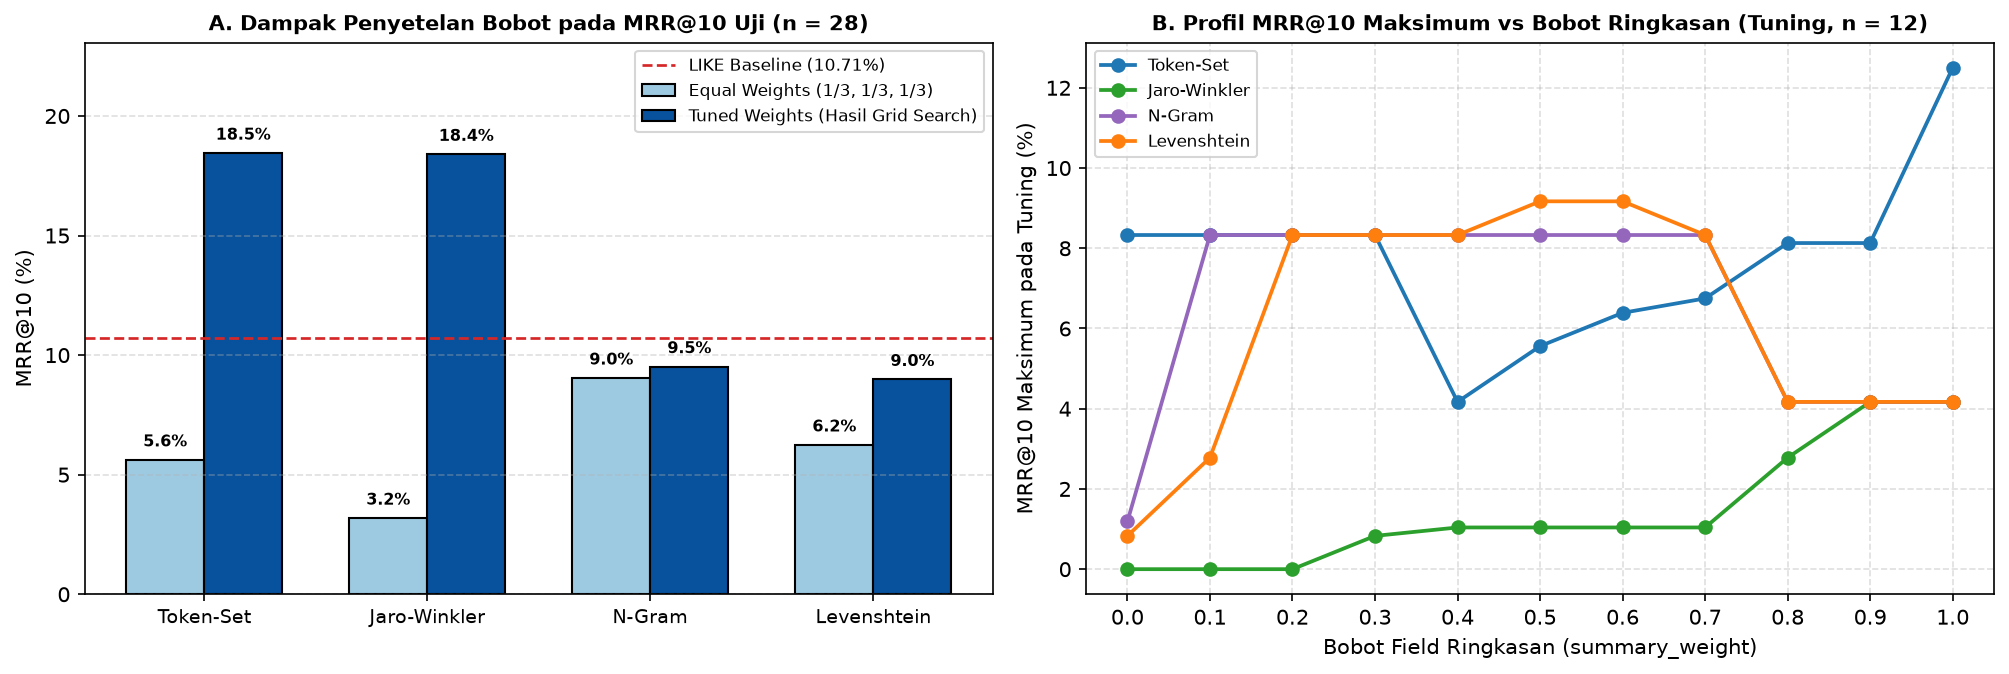

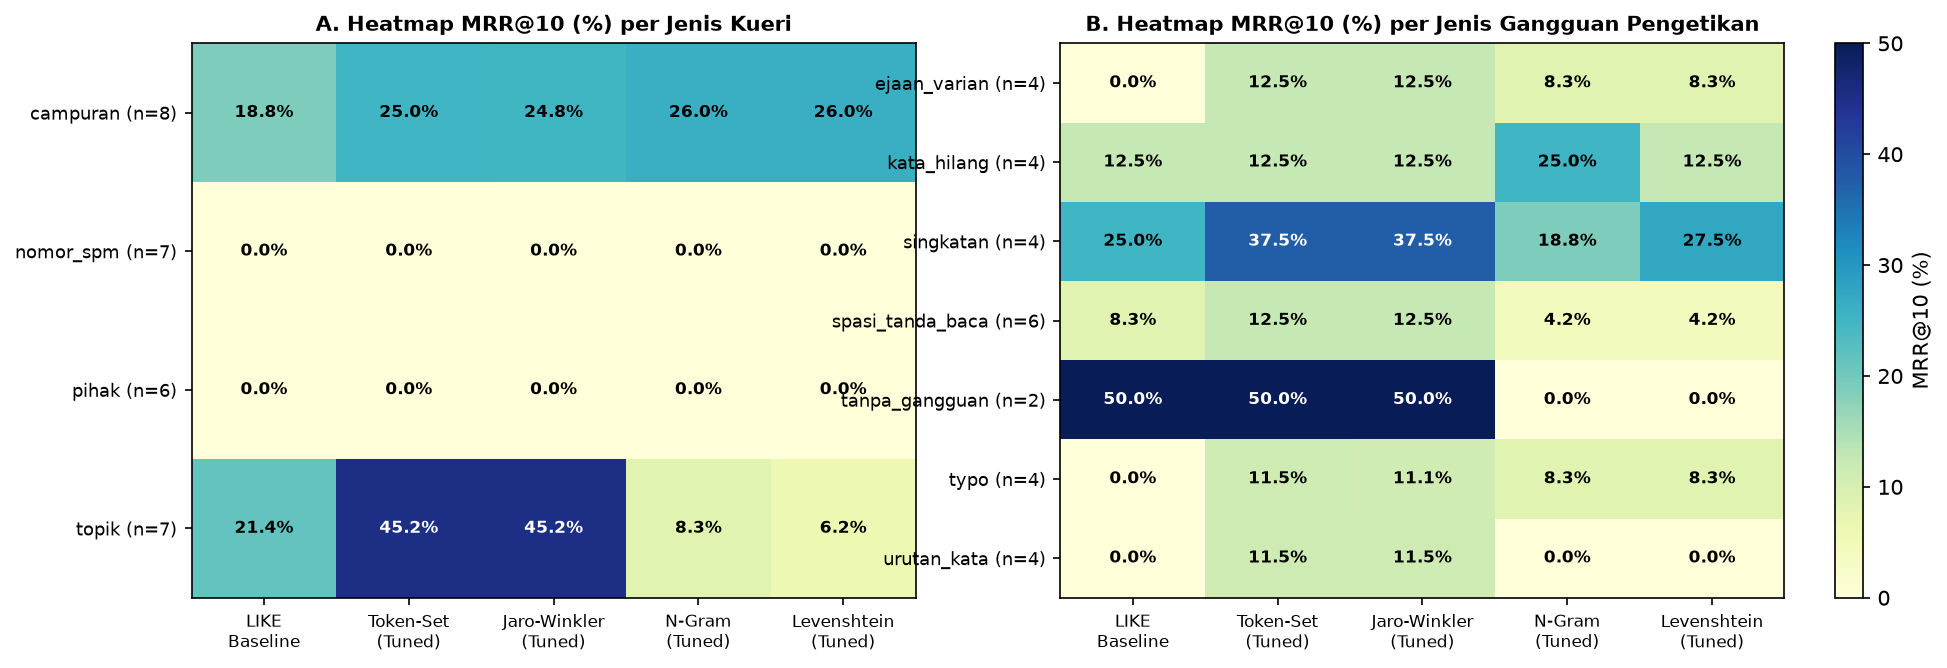

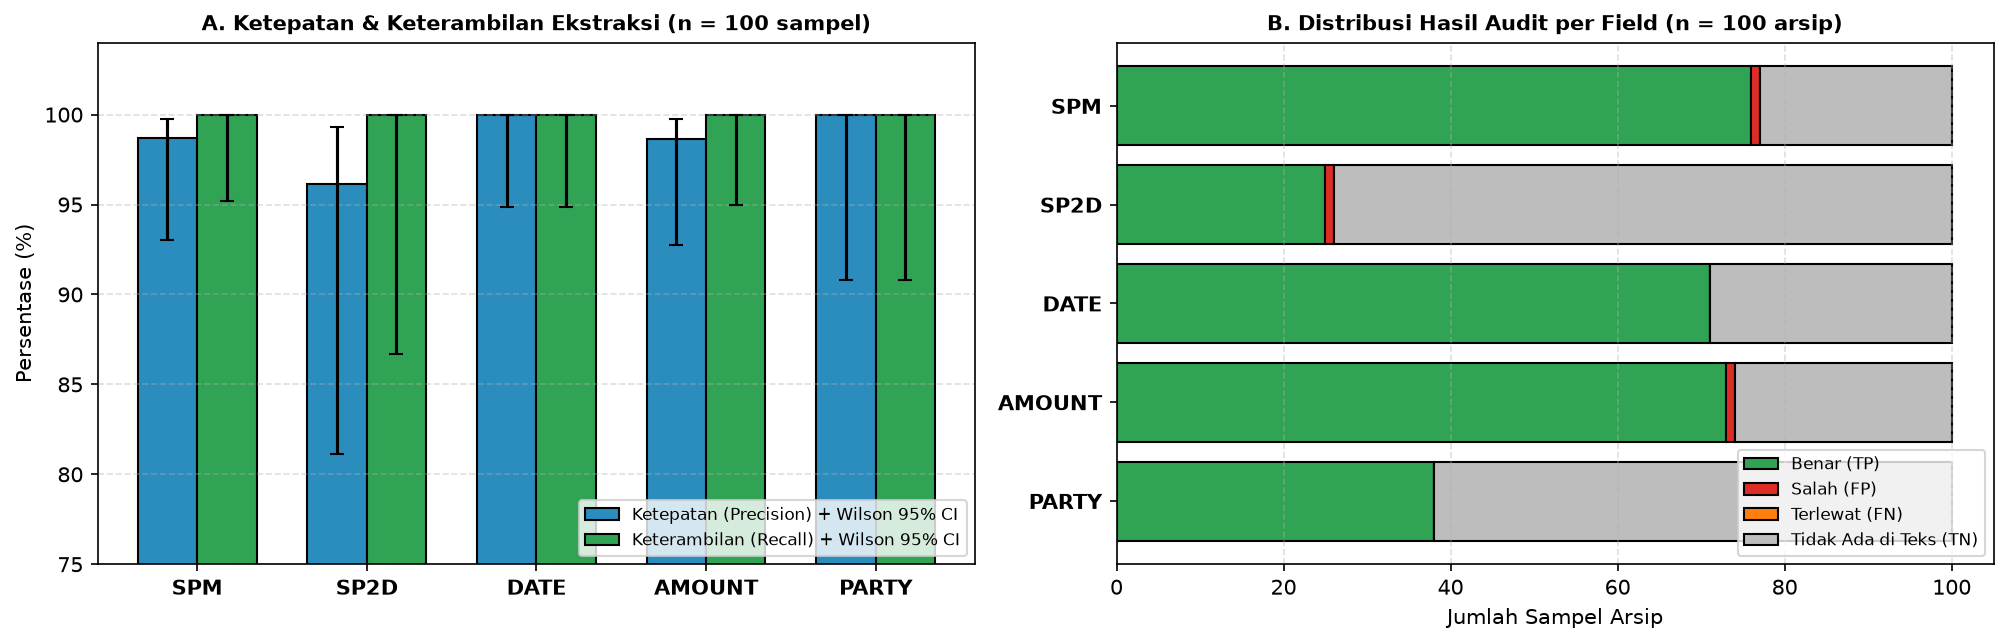

In [12]:
# =====================================================================
# SEL 12: GRAFIK PUBLIKASI ILMIAH (4 VISUALISASI 300 DPI) & EKSPOR TABEL CSV
# Mencakup: (1) Kinerja Utama + 95% CI, (2) Dampak Tuning Bobot,
#           (3) Heatmap Diagnostik Kueri & Gangguan, (4) Audit Ekstraksi Metadata
# =====================================================================
export_dir = Path("output/colab_export")
export_dir.mkdir(parents=True, exist_ok=True)

# 1. Ekspor seluruh tabel CSV utama untuk lampiran/bab hasil
df_main_summary.to_csv(export_dir / "tabel_1_evaluasi_utama_test.csv", index=False)
df_main_summary.to_csv(export_dir / "tabel_evaluasi_utama_test.csv", index=False)
df_multi.to_csv(export_dir / "tabel_2_uji_wilcoxon_holm.csv", index=False)
pd.DataFrame(weight_impact_rows).to_csv(export_dir / "tabel_3_dampak_tuning_bobot.csv", index=False)
df_audit_table.to_csv(export_dir / "tabel_4_audit_ekstraksi_metadata.csv", index=False)
print(f"[OK] 4 Tabel CSV berhasil diekspor ke direktori: {export_dir}")

# ---------------------------------------------------------------------
# GRAFIK 1: Perbandingan Kinerja Utama + 95% Bootstrap CI & Latensi
# ---------------------------------------------------------------------
fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 5.0), dpi=300)
methods_plot = ['LIKE Baseline', 'Levenshtein (Tuned)', 'Jaro-Winkler (Tuned)', 'Token-Set (Tuned)', 'N-Gram (Tuned)']
keys_plot = [('like_baseline', 'baseline'), ('levenshtein', 'tuned'), ('jaro_winkler', 'tuned'), ('token_set', 'tuned'), ('ngram', 'tuned')]

mrr_vals, mrr_err_low, mrr_err_high = [], [], []
p5_vals, p5_err_low, p5_err_high = [], [], []
hit10_vals, hit10_err_low, hit10_err_high = [], [], []
zero_vals, lat_plot_vals = [], []

for idx_k, (m_k, c_k) in enumerate(keys_plot):
    sub_k = df_test[(df_test['method'] == m_k) & (df_test['config'] == c_k)]
    m_mrr = sub_k['rr10'].mean() * 100
    ci_mrr = calc_bootstrap_ci(sub_k['rr10'], seed=42 + idx_k)
    mrr_vals.append(m_mrr)
    mrr_err_low.append(max(0.0, m_mrr - ci_mrr[0] * 100))
    mrr_err_high.append(max(0.0, ci_mrr[1] * 100 - m_mrr))

    m_p5 = sub_k['p5'].mean() * 100
    ci_p5 = calc_bootstrap_ci(sub_k['p5'], seed=142 + idx_k)
    p5_vals.append(m_p5)
    p5_err_low.append(max(0.0, m_p5 - ci_p5[0] * 100))
    p5_err_high.append(max(0.0, ci_p5[1] * 100 - m_p5))

    m_hit = sub_k['hit10'].mean() * 100
    ci_hit = calc_bootstrap_ci(sub_k['hit10'], seed=242 + idx_k)
    hit10_vals.append(m_hit)
    hit10_err_low.append(max(0.0, m_hit - ci_hit[0] * 100))
    hit10_err_high.append(max(0.0, ci_hit[1] * 100 - m_hit))

    zero_vals.append(sub_k['zero_result'].sum())
    lat_plot_vals.append(sub_k['latency_ms'].mean())

x = np.arange(len(methods_plot))
w = 0.36

ax1.bar(x - w/2, mrr_vals, w, yerr=[mrr_err_low, mrr_err_high], capsize=3, label='MRR@10 (%) + 95% CI', color='#1f77b4', edgecolor='black', alpha=0.88, error_kw=dict(lw=1.0, ecolor='#0b3c68'))
ax1.bar(x + w/2, p5_vals, w, yerr=[p5_err_low, p5_err_high], capsize=3, label='P@5 (%) + 95% CI', color='#2ca02c', edgecolor='black', alpha=0.88, error_kw=dict(lw=1.0, ecolor='#145214'))
ax1.set_title(f'A. MRR@10 & Precision@5 (n = {n_test_queries} kueri uji)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Skor Persentase (%)')
ax1.set_xticks(x)
ax1.set_xticklabels(methods_plot, rotation=22, ha='right', fontsize=8.5)
ax1.legend(loc='upper left', fontsize=8)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

bars2 = ax2.bar(x, hit10_vals, yerr=[hit10_err_low, hit10_err_high], capsize=3.5, color='#6a51a3', edgecolor='black', alpha=0.88, error_kw=dict(lw=1.1, ecolor='#2d1950'))
ax2.set_title(f'B. Keberhasilan Temu Kembali Hit@10 (n = {n_test_queries} kueri)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Hit@10 (%) + 95% CI')
ax2.set_xticks(x)
ax2.set_xticklabels(methods_plot, rotation=22, ha='right', fontsize=8.5)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.set_ylim(0, 72)
for idx_b, bar in enumerate(bars2):
    y_top = hit10_vals[idx_b] + hit10_err_high[idx_b]
    z_cnt = zero_vals[idx_b]
    ax2.text(bar.get_x() + bar.get_width()/2, y_top + 1.5, f"{hit10_vals[idx_b]:.1f}%\n(0-res: {int(z_cnt)})", ha='center', va='bottom', fontweight='bold', fontsize=7.5)

bars3 = ax3.bar(x, lat_plot_vals, color='#e6550d', edgecolor='black', alpha=0.88)
ax3.set_title(f'C. Rata-rata Latensi Pencarian (n = {n_test_queries} kueri)', fontsize=10, fontweight='bold')
ax3.set_ylabel('Latensi per Kueri (ms)')
ax3.set_xticks(x)
ax3.set_xticklabels(methods_plot, rotation=22, ha='right', fontsize=8.5)
ax3.grid(axis='y', linestyle='--', alpha=0.4)
max_lat = max(lat_plot_vals) if lat_plot_vals else 10.0
ax3.set_ylim(0, max_lat * 1.18)
for bar in bars3:
    y = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, y + max_lat * 0.02, f"{y:.1f} ms", ha='center', va='bottom', fontweight='bold', fontsize=8)

plt.tight_layout()
fig1_path = export_dir / "fig_perbandingan_kinerja_300dpi.png"
fig1.savefig(fig1_path, dpi=300)
print(f"[OK] Grafik 1 (Kinerja Utama & Latensi) disimpan ke: {fig1_path}")
plt.show()

# ---------------------------------------------------------------------
# GRAFIK 2: Dampak Penyetelan Bobot (Equal vs Tuned) & Sensitivitas Bobot
# ---------------------------------------------------------------------
fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(13.5, 4.6), dpi=300)
fuzzy_labels = ['Token-Set', 'Jaro-Winkler', 'N-Gram', 'Levenshtein']
fuzzy_keys = ['token_set', 'jaro_winkler', 'ngram', 'levenshtein']
eq_mrr_vals = [df_test[(df_test['method'] == m) & (df_test['config'] == 'equal')]['rr10'].mean() * 100 for m in fuzzy_keys]
tu_mrr_vals = [df_test[(df_test['method'] == m) & (df_test['config'] == 'tuned')]['rr10'].mean() * 100 for m in fuzzy_keys]
like_mrr = df_test[df_test['method'] == 'like_baseline']['rr10'].mean()

xf = np.arange(len(fuzzy_labels))
wf = 0.35
b_eq = ax2a.bar(xf - wf/2, eq_mrr_vals, wf, label='Equal Weights (1/3, 1/3, 1/3)', color='#9ecae1', edgecolor='black')
b_tu = ax2a.bar(xf + wf/2, tu_mrr_vals, wf, label='Tuned Weights (Hasil Grid Search)', color='#08519c', edgecolor='black')
ax2a.axhline(like_mrr * 100, color='#d62728', linestyle='--', linewidth=1.3, label=f'LIKE Baseline ({like_mrr*100:.2f}%)')
ax2a.set_title(f'A. Dampak Penyetelan Bobot pada MRR@10 Uji (n = {n_test_queries})', fontsize=10, fontweight='bold')
ax2a.set_ylabel('MRR@10 (%)')
ax2a.set_xticks(xf)
ax2a.set_xticklabels(fuzzy_labels, fontsize=9)
ax2a.set_ylim(0, max(tu_mrr_vals) * 1.25)
ax2a.legend(loc='upper right', fontsize=8)
ax2a.grid(axis='y', linestyle='--', alpha=0.4)
for bar in list(b_eq) + list(b_tu):
    yv = bar.get_height()
    ax2a.text(bar.get_x() + bar.get_width()/2, yv + 0.4, f"{yv:.1f}%", ha='center', va='bottom', fontsize=7.5, fontweight='bold')

# Panel B: Sensitivitas Bobot Ringkasan (summary_weight) terhadap MRR@10 pada Tuning Split
colors_m = {'token_set': '#1f77b4', 'jaro_winkler': '#2ca02c', 'levenshtein': '#ff7f0e', 'ngram': '#9467bd'}
for m_k, lbl_k in zip(fuzzy_keys, fuzzy_labels):
    sub_tun = df_tuning[df_tuning['matcher'] == m_k].groupby('summary_weight')['mrr_at_10'].max().reset_index()
    ax2b.plot(sub_tun['summary_weight'], sub_tun['mrr_at_10'] * 100, marker='o', linewidth=1.8, label=lbl_k, color=colors_m[m_k])
ax2b.set_title('B. Profil MRR@10 Maksimum vs Bobot Ringkasan (Tuning, n = 12)', fontsize=10, fontweight='bold')
ax2b.set_xlabel('Bobot Field Ringkasan (summary_weight)')
ax2b.set_ylabel('MRR@10 Maksimum pada Tuning (%)')
ax2b.set_xticks(np.linspace(0.0, 1.0, 11))
ax2b.legend(loc='upper left', fontsize=8)
ax2b.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
fig2_path = export_dir / "fig_dampak_tuning_bobot_300dpi.png"
fig2.savefig(fig2_path, dpi=300)
print(f"[OK] Grafik 2 (Dampak Penyetelan Bobot) disimpan ke: {fig2_path}")
plt.show()

# ---------------------------------------------------------------------
# GRAFIK 3: Heatmap Diagnostik Jenis Kueri & Gangguan Pengetikan
# ---------------------------------------------------------------------
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(14.5, 4.8), dpi=300)
method_cols = ['like_baseline', 'token_set', 'jaro_winkler', 'ngram', 'levenshtein']
method_col_labels = ['LIKE\nBaseline', 'Token-Set\n(Tuned)', 'Jaro-Winkler\n(Tuned)', 'N-Gram\n(Tuned)', 'Levenshtein\n(Tuned)']

# Matriks Jenis Kueri
qtype_mat = qtype_summary.set_index('Jenis Kueri')[method_cols].values * 100
qtype_rows = [f"{r['Jenis Kueri']} (n={int(r['n Kueri'])})" for _, r in qtype_summary.iterrows()]
im3a = ax3a.imshow(qtype_mat, cmap='YlGnBu', aspect='auto', vmin=0, vmax=50)
ax3a.set_title('A. Heatmap MRR@10 (%) per Jenis Kueri', fontsize=10, fontweight='bold')
ax3a.set_xticks(np.arange(len(method_col_labels)))
ax3a.set_xticklabels(method_col_labels, fontsize=8)
ax3a.set_yticks(np.arange(len(qtype_rows)))
ax3a.set_yticklabels(qtype_rows, fontsize=8.5)
for i in range(qtype_mat.shape[0]):
    for j in range(qtype_mat.shape[1]):
        val = qtype_mat[i, j]
        txt_color = 'white' if val > 28 else 'black'
        ax3a.text(j, i, f"{val:.1f}%", ha='center', va='center', color=txt_color, fontsize=8, fontweight='bold')

# Matriks Jenis Gangguan
noise_mat = noise_summary.set_index('Jenis Gangguan')[method_cols].values * 100
noise_rows = [f"{r['Jenis Gangguan']} (n={int(r['n Kueri'])})" for _, r in noise_summary.iterrows()]
im3b = ax3b.imshow(noise_mat, cmap='YlGnBu', aspect='auto', vmin=0, vmax=50)
ax3b.set_title('B. Heatmap MRR@10 (%) per Jenis Gangguan Pengetikan', fontsize=10, fontweight='bold')
ax3b.set_xticks(np.arange(len(method_col_labels)))
ax3b.set_xticklabels(method_col_labels, fontsize=8)
ax3b.set_yticks(np.arange(len(noise_rows)))
ax3b.set_yticklabels(noise_rows, fontsize=8.5)
for i in range(noise_mat.shape[0]):
    for j in range(noise_mat.shape[1]):
        val = noise_mat[i, j]
        txt_color = 'white' if val > 28 else 'black'
        ax3b.text(j, i, f"{val:.1f}%", ha='center', va='center', color=txt_color, fontsize=8, fontweight='bold')

fig3.colorbar(im3b, ax=[ax3a, ax3b], fraction=0.025, pad=0.03, label='MRR@10 (%)')
fig3_path = export_dir / "fig_diagnostik_jenis_dan_gangguan_300dpi.png"
fig3.savefig(fig3_path, dpi=300, bbox_inches='tight')
print(f"[OK] Grafik 3 (Heatmap Diagnostik Kueri & Gangguan) disimpan ke: {fig3_path}")
plt.show()

# ---------------------------------------------------------------------
# GRAFIK 4: Audit Akurasi Ekstraksi Metadata (Wilson 95% CI & Komposisi)
# ---------------------------------------------------------------------
fig4, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(13.5, 4.4), dpi=300)
fld_labels = [fld.upper() for fld in fields_audit.keys()]
prec_vals = [fields_audit[f]['ketepatan'] * 100 for f in fields_audit]
prec_low = [max(0.0, fields_audit[f]['ketepatan']*100 - fields_audit[f]['wilson_ci_ketepatan'][0]*100) for f in fields_audit]
prec_high = [max(0.0, fields_audit[f]['wilson_ci_ketepatan'][1]*100 - fields_audit[f]['ketepatan']*100) for f in fields_audit]
rec_vals = [fields_audit[f]['keterambilan'] * 100 for f in fields_audit]
rec_low = [max(0.0, fields_audit[f]['keterambilan']*100 - fields_audit[f]['wilson_ci_keterambilan'][0]*100) for f in fields_audit]
rec_high = [max(0.0, fields_audit[f]['wilson_ci_keterambilan'][1]*100 - fields_audit[f]['keterambilan']*100) for f in fields_audit]

xa = np.arange(len(fld_labels))
wa = 0.35
ax4a.bar(xa - wa/2, prec_vals, wa, yerr=[prec_low, prec_high], capsize=3.5, label='Ketepatan (Precision) + Wilson 95% CI', color='#2b8cbe', edgecolor='black')
ax4a.bar(xa + wa/2, rec_vals, wa, yerr=[rec_low, rec_high], capsize=3.5, label='Keterambilan (Recall) + Wilson 95% CI', color='#31a354', edgecolor='black')
ax4a.set_title(f'A. Ketepatan & Keterambilan Ekstraksi (n = {total_audit} sampel)', fontsize=10, fontweight='bold')
ax4a.set_ylabel('Persentase (%)')
ax4a.set_xticks(xa)
ax4a.set_xticklabels(fld_labels, fontweight='bold')
ax4a.set_ylim(75, 104)
ax4a.legend(loc='lower right', fontsize=8)
ax4a.grid(axis='y', linestyle='--', alpha=0.4)

tp_list = np.array([fields_audit[f]['n_benar'] for f in fields_audit])
fp_list = np.array([fields_audit[f]['n_salah'] for f in fields_audit])
fn_list = np.array([fields_audit[f]['n_terlewat'] for f in fields_audit])
tn_list = np.array([fields_audit[f]['n_tidak_ada_di_teks'] for f in fields_audit])

ax4b.barh(xa, tp_list, label='Benar (TP)', color='#31a354', edgecolor='black')
ax4b.barh(xa, fp_list, left=tp_list, label='Salah (FP)', color='#de2d26', edgecolor='black')
ax4b.barh(xa, fn_list, left=tp_list+fp_list, label='Terlewat (FN)', color='#ff7f0e', edgecolor='black')
ax4b.barh(xa, tn_list, left=tp_list+fp_list+fn_list, label='Tidak Ada di Teks (TN)', color='#bdbdbd', edgecolor='black')
ax4b.set_title(f'B. Distribusi Hasil Audit per Field (n = {total_audit} arsip)', fontsize=10, fontweight='bold')
ax4b.set_xlabel('Jumlah Sampel Arsip')
ax4b.set_yticks(xa)
ax4b.set_yticklabels(fld_labels, fontweight='bold')
ax4b.invert_yaxis()
ax4b.legend(loc='lower right', fontsize=8)
ax4b.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
fig4_path = export_dir / "fig_audit_ekstraksi_metadata_300dpi.png"
fig4.savefig(fig4_path, dpi=300)
print(f"[OK] Grafik 4 (Audit Ekstraksi Metadata) disimpan ke: {fig4_path}")
plt.show()

In [13]:
# =====================================================================
# SEL 13: GENERASI RINGKASAN EKSEKUTIF OTOMATIS DARI ANGKA (TEMPLAT RESMI)
# Aturan: Model terbaik ditetapkan a-priori dari kelompok tuning (bebas bias seleksi),
# seluruh kalimat dibangkitkan dari variabel angka tanpa teks manual.
# =====================================================================
# 1. Ambil model terbaik dari fase tuning (a-priori: MRR@10 -> P@5 -> jarak ke bobot seimbang)
df_tuning_s13 = df_tuning.copy()
df_tuning_s13['dist_to_equal'] = (
    (df_tuning_s13['summary_weight'] - 1/3)**2 +
    (df_tuning_s13['spm_weight'] - 1/3)**2 +
    (df_tuning_s13['party_weight'] - 1/3)**2
)
best_tuning_per_matcher = df_tuning_s13.sort_values(
    by=['mrr_at_10', 'precision_at_5', 'dist_to_equal'], ascending=[False, False, True]
).groupby('matcher', as_index=False).first()
best_tuning_winner = best_tuning_per_matcher.sort_values(
    by=['mrr_at_10', 'precision_at_5', 'dist_to_equal'], ascending=[False, False, True]
).iloc[0]
best_m = best_tuning_winner['matcher']
best_cfg = 'tuned'

# 2. Hitung metrik pada test split
like_mrr = df_test[df_test['method'] == 'like_baseline']['rr10'].mean()
like_p5 = df_test[df_test['method'] == 'like_baseline']['p5'].mean()
like_zero = int(df_test[df_test['method'] == 'like_baseline']['zero_result'].sum())
like_hit10 = df_test[df_test['method'] == 'like_baseline']['hit10'].mean()
like_r10 = df_test[df_test['method'] == 'like_baseline']['r10'].mean()

df_best_sub = df_test[(df_test['method'] == best_m) & (df_test['config'] == best_cfg)]
best_fuzzy_mrr = df_best_sub['rr10'].mean()
best_fuzzy_zero = int(df_best_sub['zero_result'].sum())
best_fuzzy_p5 = df_best_sub['p5'].mean()
best_fuzzy_hit10 = df_best_sub['hit10'].mean()
best_fuzzy_r10 = df_best_sub['r10'].mean()
best_fuzzy_unjudged = df_best_sub['unjudged_in_top10'].mean()

mrr_best_ci = calc_bootstrap_ci(df_best_sub['rr10'])
mrr_like_ci = calc_bootstrap_ci(df_test[df_test['method'] == 'like_baseline']['rr10'])
hit10_best_ci = calc_bootstrap_ci(df_best_sub['hit10'])
hit10_like_ci = calc_bootstrap_ci(df_test[df_test['method'] == 'like_baseline']['hit10'])

pct_like_zero = (like_zero / n_test_queries) * 100.0
pct_best_zero = (best_fuzzy_zero / n_test_queries) * 100.0

# Bangkitkan teks bobot secara dinamis dari tabel tuning
weights_desc = []
for _, r_w in best_tuning_per_matcher.iterrows():
    weights_desc.append(f"   - {r_w['matcher']:<12}: Ringkasan={r_w['summary_weight']:.1f}, SPM={r_w['spm_weight']:.1f}, Pihak={r_w['party_weight']:.1f} (Tuning MRR={r_w['mrr_at_10']:.4f})")
weights_block = "\n".join(weights_desc)

template_summary = f"""
RINGKASAN EKSEKUTIF TEMUAN PENELITIAN (DIBANGKITKAN SECARA OTOMATIS DARI DATA)
--------------------------------------------------------------------------------
1. Perbandingan Kinerja Utama (Evaluasi A-Priori Model Terbaik):
   Model terpilih dari fase tuning ('{best_m} ({best_cfg})') diuji pada kelompok test (n = {n_test_queries} kueri).
   Model ini menghasilkan MRR@10 sebesar {best_fuzzy_mrr:.4f} (95% CI: [{mrr_best_ci[0]:.4f}, {mrr_best_ci[1]:.4f}])
   dan Precision@5 sebesar {best_fuzzy_p5:.4f}, dibandingkan LIKE Baseline yang memperoleh
   MRR@10 sebesar {like_mrr:.4f} (95% CI: [{mrr_like_ci[0]:.4f}, {mrr_like_ci[1]:.4f}]) dan P@5 sebesar {like_p5:.4f}.
   Interval kepercayaan kedua metode sebagian saling bertumpang tindih pada ukuran sampel kueri saat ini.

2. Efektivitas Temu Kembali Dokumen Relevan (Hit@10 & Kueri Nol Hasil):
   Sistem eksisting (LIKE Baseline) mengalami kegagalan temu kembali pada {like_zero} dari {n_test_queries} kueri ({pct_like_zero:.1f}%)
   dengan capaian Hit@10 sebesar {like_hit10:.4f} (95% CI: [{hit10_like_ci[0]:.4f}, {hit10_like_ci[1]:.4f}]).
   Metode '{best_m} ({best_cfg})' meningkatkan Hit@10 menjadi {best_fuzzy_hit10:.4f} (95% CI: [{hit10_best_ci[0]:.4f}, {hit10_best_ci[1]:.4f}]).
   Meskipun metode fuzzy secara algoritmik selalu menampilkan 10 dokumen teratas (sehingga kueri nol hasil menjadi {best_fuzzy_zero}),
   sebanyak {(1.0 - best_fuzzy_hit10)*100:.1f}% kueri masih belum menemukan dokumen relevan di 10 besar.
   Tingginya rata-rata dokumen belum dinilai di Top-10 ({best_fuzzy_unjudged:.2f} dokumen) mengonfirmasi bahwa evaluasi ini
   merupakan batas bawah (lower-bound estimate) efektivitas temu kembali.

3. Penyetelan Bobot Multi-Field (Hasil Optimasi Kelompok Tuning, n = 12):
   Alokasi bobot optimal yang dihasilkan dari grid search:
{weights_block}
   Pada model terpilih ({best_m}), alokasi bobot terbesar berada pada field Ringkasan ({best_tuning_winner['summary_weight']:.1f}),
   yang mengonfirmasi bahwa kueri pencarian arsip didominasi oleh kata kunci deskripsi kegiatan penatausahaan.
"""

print(template_summary)


RINGKASAN EKSEKUTIF TEMUAN PENELITIAN (DIBANGKITKAN SECARA OTOMATIS DARI DATA)
--------------------------------------------------------------------------------
1. Perbandingan Kinerja Utama (Evaluasi A-Priori Model Terbaik):
   Model terpilih dari fase tuning ('token_set (tuned)') diuji pada kelompok test (n = 28 kueri).
   Model ini menghasilkan MRR@10 sebesar 0.1845 (95% CI: [0.0863, 0.3006])
   dan Precision@5 sebesar 0.0929, dibandingkan LIKE Baseline yang memperoleh
   MRR@10 sebesar 0.1071 (95% CI: [0.0179, 0.1964]) dan P@5 sebesar 0.0643.
   Interval kepercayaan kedua metode sebagian saling bertumpang tindih pada ukuran sampel kueri saat ini.

2. Efektivitas Temu Kembali Dokumen Relevan (Hit@10 & Kueri Nol Hasil):
   Sistem eksisting (LIKE Baseline) mengalami kegagalan temu kembali pada 18 dari 28 kueri (64.3%)
   dengan capaian Hit@10 sebesar 0.1786 (95% CI: [0.0357, 0.3214]).
   Metode 'token_set (tuned)' meningkatkan Hit@10 menjadi 0.3929 (95% CI: [0.2143, 0.5714]).
   Meski

---
## ⚠️ Keterbatasan Penelitian (Academic Limitations)

Penyajian hasil evaluasi pada penelitian ini wajib dimaknai dalam batas-batas metodologis berikut:
1. **Seluruh Kueri Bersifat Sintetis:** Seluruh kueri uji (28 dari 28 kueri pada test split, dan 12 dari 12 pada tuning split; 0 kueri nyata pengguna operasional) merupakan kueri sintetis terstruktur yang dibangkitkan dari korpus arsip untuk mensimulasikan ragam variasi pengetikan manusia (*noise models*).
2. **Anotasi Relevansi Tunggal:** Penilaian relevansi utama diselesaikan oleh peneliti tunggal, sementara verifikasi ganda arsiparis independen masih berstatus sampel verifikasi.
3. **Skala Pengguna Terbatas:** Uji coba belum melibatkan lebih dari 5 pengguna akhir simultan di lingkungan operasional dinas.
4. **Salinan Data Statis:** Pengujian menggunakan salinan *dump* basis data statis 1.737 arsip (dengan rentang pencatatan dokumen arsip historis di lingkungan e-Arsip), bukan pengujian *live streaming* basis data produksi e-Arsip yang mengalami mutasi data harian.

---
## 🔒 Prosedur Penutupan Sesi & Keamanan Runtime

Sebelum menutup sesi Google Colab atau mengunggah perubahan ke repositori:
1. **Bersihkan Seluruh Keluaran Sel (*Clear All Outputs*):**
   Pilih menu `Edit` $\to$ `Clear all outputs` agar tidak ada angka atau grafik yang tertinggal di berkas JSON `.ipynb` secara permanen.
2. **Putuskan Runtime (*Disconnect & Delete Runtime*):**
   Pilih menu panah bawah di pojok kanan atas Colab $\to$ pilih **`Disconnect and delete runtime`** untuk menghapus seluruh berkas sementara di lingkungan *cloud*.
3. **Jaga Kerahasiaan:**
   Jangan membagikan tautan notebook atau folder Drive secara publik.